# iBims-1 GT 기반 검증: V2 Raw vs 우리 방식 (RANSAC)
**storageroom_06** (창고 선반 이미지)

GPU 런타임 필수 (런타임 > 런타임 유형 변경 > T4 GPU)

In [2]:
# [셀 1] 간단한 방법: 직접 업로드
!pip install transformers accelerate opencv-contrib-python-headless -q

from google.colab import files
print('Kaggle에서 Download 버튼 눌러서 받은 zip 파일을 업로드하세요:')
uploaded = files.upload()

import zipfile
zip_name = list(uploaded.keys())[0]
with zipfile.ZipFile(zip_name, 'r') as z:
    z.extractall('ibims-1')

print('압축 해제 완료')

Kaggle에서 Download 버튼 눌러서 받은 zip 파일을 업로드하세요:


Saving archive.zip to archive.zip
압축 해제 완료


In [3]:
# [셀 2] 임포트 & 모델 로드
import torch
import numpy as np
import cv2
import matplotlib.pyplot as plt
import scipy.io as sio
from PIL import Image, ImageOps
from transformers import pipeline
import pandas as pd
import os

print('모델 로딩 중...')
depth_pipe = pipeline(
    task='depth-estimation',
    model='depth-anything/Depth-Anything-V2-Metric-Indoor-Small-hf',
    device=0 if torch.cuda.is_available() else -1
)
print('모델 로딩 완료')

모델 로딩 중...


/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:112: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


config.json:   0%|          | 0.00/1.06k [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/99.2M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/287 [00:00<?, ?it/s]

preprocessor_config.json:   0%|          | 0.00/437 [00:00<?, ?B/s]

모델 로딩 완료


In [9]:
# [셀 3] iBims-1 데이터 로드 (storageroom_01)
DATA_DIR = 'ibims-1/iBims-1'
IMAGE_NAME = 'storageroom_01'

# RGB 이미지 로드
rgb_path = os.path.join(DATA_DIR, 'rgb', f'{IMAGE_NAME}.png')
img = Image.open(rgb_path).convert('RGB')
img_np = np.array(img)
H_img, W_img = img_np.shape[:2]

# GT depth 로드 (.mat 파일)
mat_path = os.path.join(DATA_DIR, 'ibims1_core_mat', f'{IMAGE_NAME}.mat')
mat_data = sio.loadmat(mat_path)

# .mat 파일 내부 키 확인
print('=== .mat 파일 키 목록 ===')
for key in mat_data.keys():
    if not key.startswith('_'):
        val = mat_data[key]
        if hasattr(val, 'shape'):
            print(f'  {key}: shape={val.shape}, dtype={val.dtype}')
        else:
            print(f'  {key}: {type(val)}')

print(f'\n이미지 크기: {W_img}x{H_img}')

=== .mat 파일 키 목록 ===
  data: shape=(1, 1), dtype=[('image_name', 'O'), ('calib', 'O'), ('rgb', 'O'), ('depth', 'O'), ('mask_transp', 'O'), ('mask_invalid', 'O'), ('mask_floor', 'O'), ('mask_table', 'O'), ('mask_wall', 'O'), ('edges', 'O'), ('mask_floor_paras', 'O'), ('mask_table_paras', 'O'), ('mask_wall_paras', 'O')]

이미지 크기: 640x480


GT depth shape: (480, 640)
GT depth 범위: 1.37m ~ 3.48m
GT 유효 픽셀: 307,157 (100.0%)
mask_invalid 픽셀: 307,200
벽 마스크: 51,996개
바닥 마스크: 0개
테이블 마스크: 0개


/tmp/ipykernel_671/447274043.py:50: UserWarning: Glyph 54217 (\N{HANGUL SYLLABLE PYEONG}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_671/447274043.py:50: UserWarning: Glyph 47732 (\N{HANGUL SYLLABLE MYEON}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_671/447274043.py:50: UserWarning: Glyph 47560 (\N{HANGUL SYLLABLE MA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_671/447274043.py:50: UserWarning: Glyph 49828 (\N{HANGUL SYLLABLE SEU}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_671/447274043.py:50: UserWarning: Glyph 53356 (\N{HANGUL SYLLABLE KEU}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_671/447274043.py:50: UserWarning: Glyph 48744 (\N{HANGUL SYLLABLE BBAL}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_671/447274043.py:50: UserWarning: Glyph 44053 (\N{HANGUL SYLLABLE GANG}) missing from font(s) DejaVu Sans.
  plt.tight_layout()


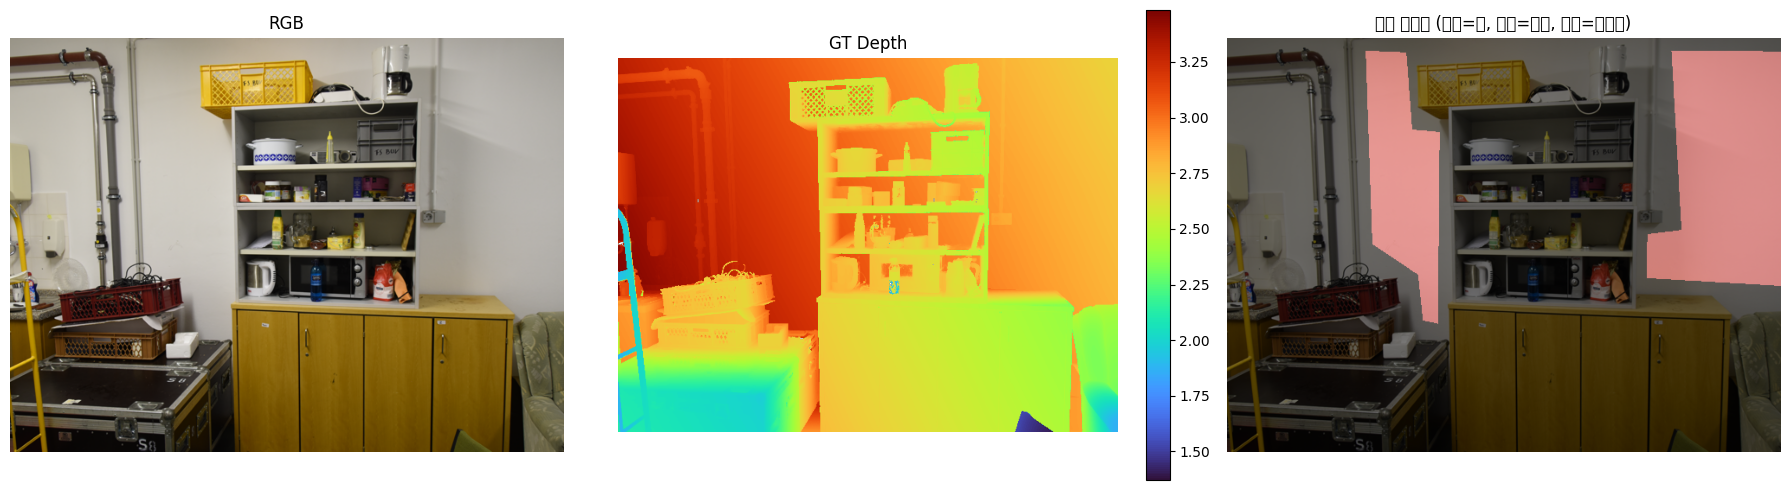

In [13]:
# [셀 4] GT depth 추출 수정버전
raw = None
for key in mat_data.keys():
    if not key.startswith('_'):
        raw = mat_data[key]
        break

data = raw[0, 0]

# GT depth 추출 (mask_invalid 적용 안 함)
gt_depth = np.array(data['depth']).astype(np.float32)

# 0만 NaN으로 처리 (inf/nan 없음 확인됨)
gt_depth[gt_depth <= 0] = np.nan

# 마스크 추출
mask_invalid = np.array(data['mask_invalid']).astype(bool)
mask_wall    = np.array(data['mask_wall']).astype(bool)
mask_floor   = np.array(data['mask_floor']).astype(bool)
mask_table   = np.array(data['mask_table']).astype(bool)

valid_count = (~np.isnan(gt_depth)).sum()
print(f'GT depth shape: {gt_depth.shape}')
print(f'GT depth 범위: {np.nanmin(gt_depth):.2f}m ~ {np.nanmax(gt_depth):.2f}m')
print(f'GT 유효 픽셀: {valid_count:,} ({valid_count/gt_depth.size*100:.1f}%)')
print(f'mask_invalid 픽셀: {mask_invalid.sum():,}')
print(f'벽 마스크: {mask_wall.sum():,}개')
print(f'바닥 마스크: {mask_floor.sum():,}개')
print(f'테이블 마스크: {mask_table.sum():,}개')

# 시각화
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
axes[0].imshow(img_np)
axes[0].set_title('RGB')
axes[0].axis('off')

im = axes[1].imshow(gt_depth, cmap='turbo')
axes[1].set_title('GT Depth')
axes[1].axis('off')
plt.colorbar(im, ax=axes[1], fraction=0.046)

plane_vis = np.zeros((*gt_depth.shape, 3), dtype=np.uint8)
plane_vis[mask_wall]  = [255, 100, 100]
plane_vis[mask_floor] = [100, 255, 100]
plane_vis[mask_table] = [100, 100, 255]
axes[2].imshow(img_np)
axes[2].imshow(plane_vis, alpha=0.5)
axes[2].set_title('평면 마스크 (빨강=벽, 초록=바닥, 파랑=테이블)')
axes[2].axis('off')
plt.tight_layout()
plt.show()

전체 픽셀: 307,200
GT 유효 픽셀: 307,157 (100.0%)


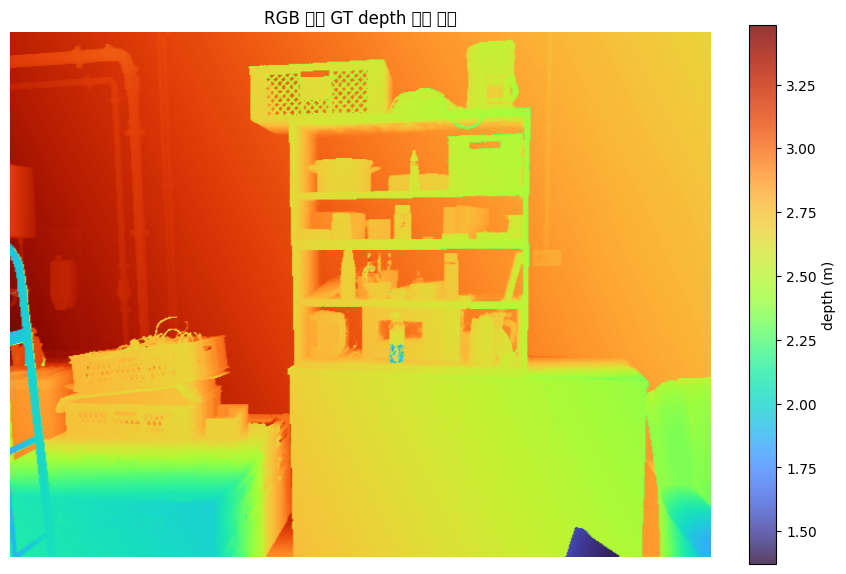

In [14]:
# GT depth sparse 확인
total = gt_depth.size
valid_gt = (~np.isnan(gt_depth)).sum()
print(f'전체 픽셀: {total:,}')
print(f'GT 유효 픽셀: {valid_gt:,} ({valid_gt/total*100:.1f}%)')

# RGB 위에 GT depth 유효 픽셀 찍어보기
fig, ax = plt.subplots(1, 1, figsize=(10, 7))
ax.imshow(img_np)
ys, xs = np.where(~np.isnan(gt_depth))
sc = ax.scatter(xs, ys, c=gt_depth[ys, xs],
                cmap='turbo', s=1, alpha=0.8)
plt.colorbar(sc, ax=ax, fraction=0.046, label='depth (m)')
ax.set_title('RGB 위에 GT depth 유효 픽셀')
ax.axis('off')
plt.show()

In [15]:
# # raw depth 값 확인
# raw_depth = np.array(data['depth'])
# print(f'shape: {raw_depth.shape}')
# print(f'dtype: {raw_depth.dtype}')
# print(f'min: {raw_depth.min()}, max: {raw_depth.max()}')
# print(f'0인 픽셀: {(raw_depth == 0).sum():,}')
# print(f'inf인 픽셀: {np.isinf(raw_depth).sum():,}')
# print(f'nan인 픽셀: {np.isnan(raw_depth).sum():,}')
# print(f'양수인 픽셀: {(raw_depth > 0).sum():,}')
# print(f'\n샘플 값 (0이 아닌 것들):')
# nonzero = raw_depth[raw_depth != 0]
# if len(nonzero) > 0:
#     print(nonzero[:20])
# else:
#     print('전부 0')

V2 depth 범위: 1.32m ~ 3.79m


/tmp/ipykernel_671/2892067307.py:19: UserWarning: Glyph 48708 (\N{HANGUL SYLLABLE BI}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_671/2892067307.py:19: UserWarning: Glyph 44368 (\N{HANGUL SYLLABLE GYO}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_671/2892067307.py:19: UserWarning: Glyph 44057 (\N{HANGUL SYLLABLE GAT}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_671/2892067307.py:19: UserWarning: Glyph 51008 (\N{HANGUL SYLLABLE EUN}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_671/2892067307.py:19: UserWarning: Glyph 49353 (\N{HANGUL SYLLABLE SAEG}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_671/2892067307.py:19: UserWarning: Glyph 49345 (\N{HANGUL SYLLABLE SANG}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_671/2892067307.py:19: UserWarning: Glyph 48276 (\N{HANGUL SYLLABLE BEOM}) missing from font(s) DejaVu Sans.
  plt.tight_layout

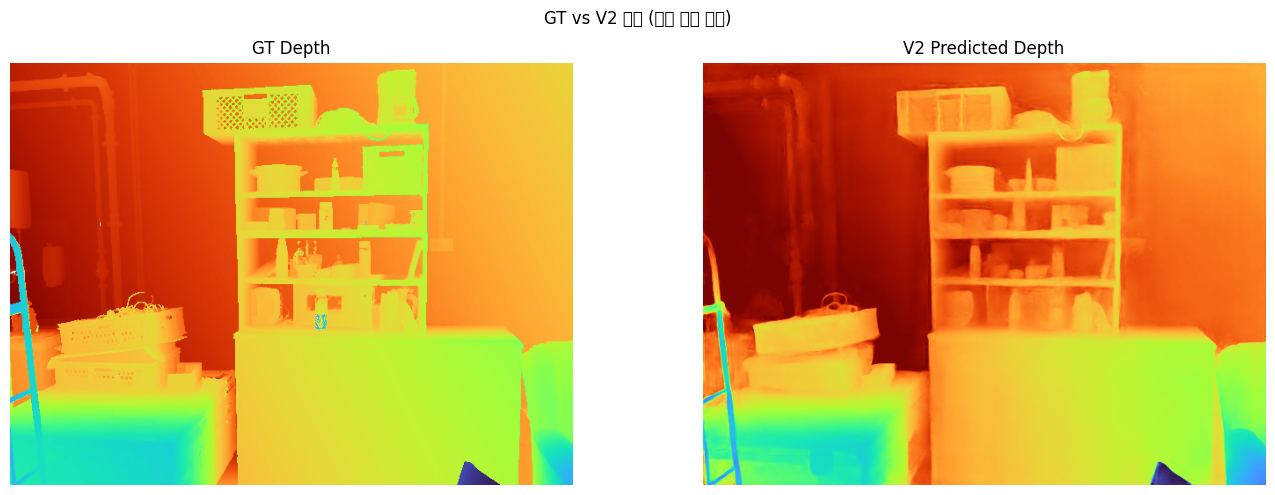

In [16]:
# [셀 5] Depth Anything V2 추정
result = depth_pipe(img)
v2_depth = np.array(result['predicted_depth']).astype(np.float32)
if v2_depth.shape != (H_img, W_img):
    v2_depth = cv2.resize(v2_depth, (W_img, H_img), interpolation=cv2.INTER_LINEAR)

print(f'V2 depth 범위: {v2_depth.min():.2f}m ~ {v2_depth.max():.2f}m')

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
vmin = np.nanmin(gt_depth)
vmax = np.nanmax(gt_depth)
axes[0].imshow(gt_depth, cmap='turbo', vmin=vmin, vmax=vmax)
axes[0].set_title('GT Depth')
axes[0].axis('off')
axes[1].imshow(v2_depth, cmap='turbo', vmin=vmin, vmax=vmax)
axes[1].set_title('V2 Predicted Depth')
axes[1].axis('off')
plt.suptitle('GT vs V2 비교 (같은 색상 범위)')
plt.tight_layout()
plt.show()

/tmp/ipykernel_671/3666214896.py:11: UserWarning: Glyph 51340 (\N{HANGUL SYLLABLE JWA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_671/3666214896.py:11: UserWarning: Glyph 54364 (\N{HANGUL SYLLABLE PYO}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_671/3666214896.py:11: UserWarning: Glyph 54869 (\N{HANGUL SYLLABLE HWAG}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_671/3666214896.py:11: UserWarning: Glyph 51064 (\N{HANGUL SYLLABLE IN}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_671/3666214896.py:11: UserWarning: Glyph 50857 (\N{HANGUL SYLLABLE YONG}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_671/3666214896.py:11: UserWarning: Glyph 44032 (\N{HANGUL SYLLABLE GA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_671/3666214896.py:11: UserWarning: Glyph 47196 (\N{HANGUL SYLLABLE RO}) missing from font(s) DejaVu Sans.
  plt.tight_layout()


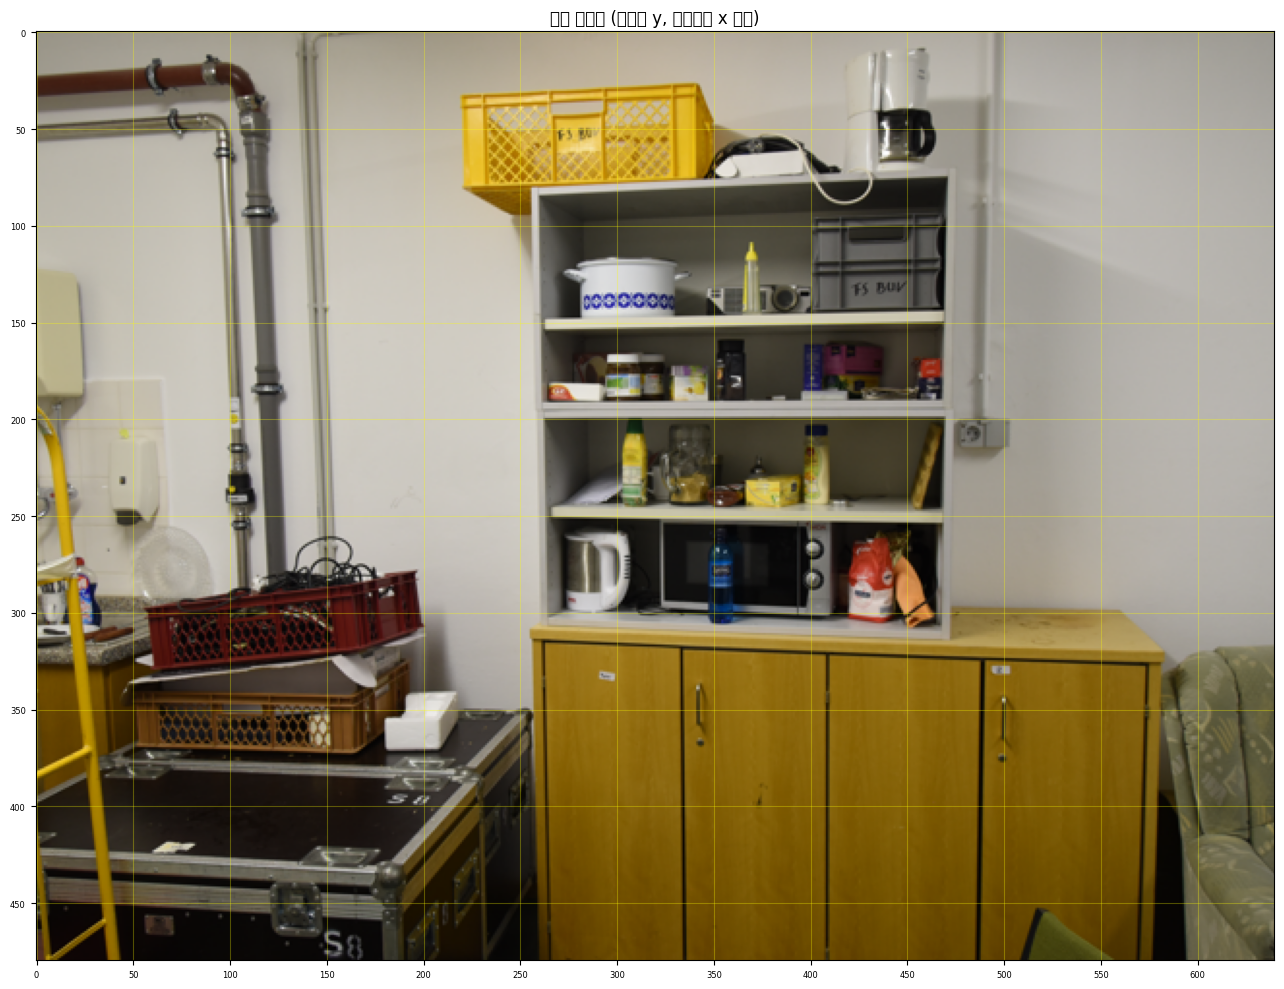

In [17]:
# [셀 6] 선반 테두리 ROI 하드코딩 (# 격자 방식)
#
# ★ 좌표 확인용 이미지 (눈금 포함) ★
fig, ax = plt.subplots(1, 1, figsize=(14, 10))
ax.imshow(img_np)
ax.set_xticks(range(0, W_img, 50))
ax.set_yticks(range(0, H_img, 50))
ax.grid(True, alpha=0.3, color='yellow')
ax.tick_params(labelsize=6)
ax.set_title('좌표 확인용 (가로빔 y, 세로기둥 x 읽기)')
plt.tight_layout()
plt.show()

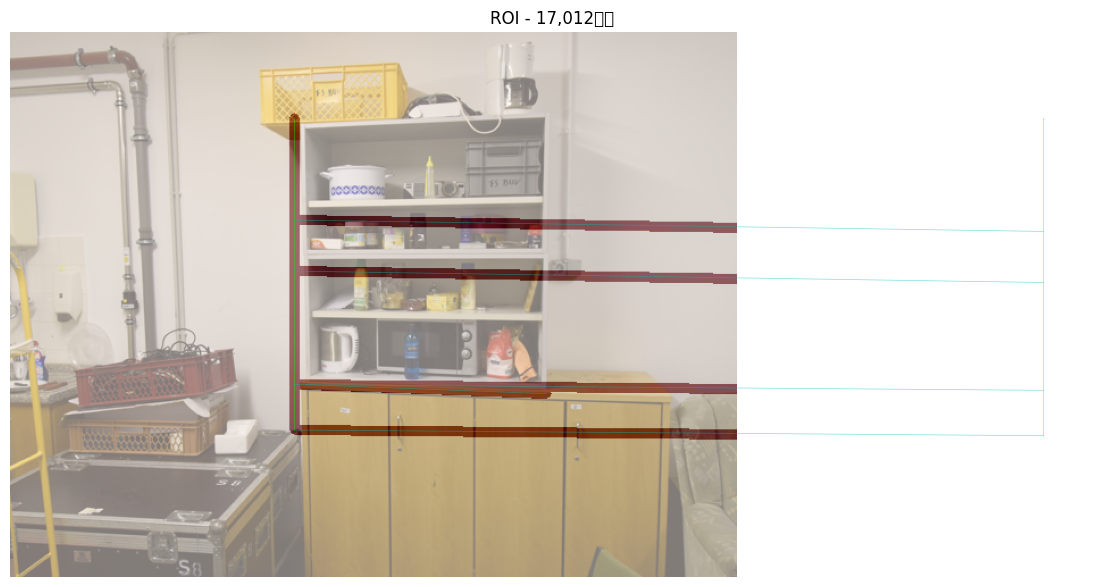

안 맞으면 h_beams, v_posts 좌표 수정 후 다시 실행


In [23]:
# [셀 7] 기울어진 선반 ROI - 선분 기반
import cv2

roi_mask = np.zeros((H_img, W_img), dtype=bool)
THICKNESS = 8  # 빔 두께 (픽셀)

# ★ 가로빔: (x1,y1) → (x2,y2) 형식으로 입력
# 눈금 이미지 보고 각 빔의 양 끝 좌표 수정
h_beams = [
    (260, 310, 472, 318),  # 1층 상단빔
    (260, 165, 910, 175),  # 2층 빔
    (250, 210, 910, 220),  # 3층 빔
]

# ★ 세로기둥: x중심, y범위
v_posts = [
    (250, 75, 350),   # 왼쪽기둥 (x, y_top, y_bottom)
    (910, 75, 355),   # 오른쪽기둥
]

# 마스크에 선 그리기
mask_img = np.zeros((H_img, W_img), dtype=np.uint8)

for x1, y1, x2, y2 in h_beams:
    cv2.line(mask_img, (x1,y1), (x2,y2), 255, THICKNESS)

for xc, yt, yb in v_posts:
    cv2.line(mask_img, (xc,yt), (xc,yb), 255, THICKNESS)

roi_mask = mask_img > 0

# 확인
fig, ax = plt.subplots(1, 1, figsize=(14, 10))
ax.imshow(img_np)
ax.imshow(roi_mask, alpha=0.5, cmap='Reds')
# 가이드선 표시
for x1,y1,x2,y2 in h_beams:
    ax.plot([x1,x2],[y1,y2], 'c-', linewidth=0.5, alpha=0.5)
for xc,yt,yb in v_posts:
    ax.plot([xc,xc],[yt,yb], 'lime', linewidth=0.5, alpha=0.5)
ax.set_title(f'ROI - {roi_mask.sum():,}픽셀')
ax.axis('off')
plt.show()
print('안 맞으면 h_beams, v_posts 좌표 수정 후 다시 실행')

In [ ]:
# [셀 8] 핵심 함수 정의
fx, fy = 525.0, 525.0
cx, cy = W_img / 2.0, H_img / 2.0

def fit_plane_ransac_svd(points_3d, n_iters=200, threshold=0.05):
    N = len(points_3d)
    if N < 10:
        return None
    best_n, best_mask = 0, None
    for _ in range(n_iters):
        idx = np.random.choice(N, 3, replace=False)
        p1, p2, p3 = points_3d[idx]
        normal = np.cross(p2 - p1, p3 - p1)
        nrm = np.linalg.norm(normal)
        if nrm < 1e-6:
            continue
        normal = normal / nrm
        d = np.dot(normal, p1)
        dists = np.abs(points_3d @ normal - d)
        n_in = (dists < threshold).sum()
        if n_in > best_n:
            best_n = n_in
            best_mask = dists < threshold
    if best_mask is None or best_mask.sum() < 10:
        return None
    inliers = points_3d[best_mask]
    centroid = inliers.mean(0)
    _, _, Vt = np.linalg.svd(inliers - centroid, full_matrices=False)
    normal = Vt[-1]
    d = np.dot(normal, centroid)
    return normal, d, best_mask.sum() / N

def split_mask_by_depth(mask, depth, n_tiers=4):
    from sklearn.cluster import KMeans
    ys, xs = np.where(mask)
    if len(ys) < n_tiers * 10:
        return [mask]
    zs = depth[ys, xs].reshape(-1, 1)
    km = KMeans(n_clusters=n_tiers, random_state=42, n_init=10).fit(zs)
    order = np.argsort(km.cluster_centers_.ravel())
    sub_masks = []
    for k in order:
        sub = np.zeros_like(mask)
        sel = km.labels_ == k
        sub[ys[sel], xs[sel]] = True
        if sub.sum() > 10:
            sub_masks.append(sub)
    return sub_masks

print('함수 정의 완료')

In [ ]:
# [셀 9] RANSAC Plane Fitting 적용
N_TIERS = int(input('Tier 수 (선반 층 수, 기본 4): ') or '4')

refined_depth = v2_depth.copy()
sub_masks = split_mask_by_depth(roi_mask, v2_depth, n_tiers=N_TIERS)
stats = []

print(f'\n=== RANSAC Plane Fitting ({len(sub_masks)}개 Tier) ===')
for i, sub_m in enumerate(sub_masks):
    ys, xs = np.where(sub_m)
    if len(ys) < 50:
        print(f'  Tier_{i}: 픽셀 부족 -> 스킵')
        continue
    zs = v2_depth[ys, xs]
    Xs = (xs - cx) * zs / fx
    Ys = (ys - cy) * zs / fy
    points = np.stack([Xs, Ys, zs], axis=1)

    res = fit_plane_ransac_svd(points, n_iters=300, threshold=0.05)
    if res is None:
        print(f'  Tier_{i}: RANSAC 실패')
        continue
    normal, d, inlier_ratio = res
    nx, ny, nz = normal
    if abs(nz) < 1e-6:
        continue

    z_plane = (d - nx * Xs - ny * Ys) / nz
    refined_depth[ys, xs] = z_plane

    print(f'  Tier_{i}: inlier {inlier_ratio*100:.0f}% | d={d:.3f}m | 픽셀 {len(ys):,}개')

# Guided Filtering (선택)
try:
    diff = refined_depth - v2_depth
    diff_smoothed = cv2.ximgproc.guidedFilter(
        guide=img_np, src=diff.astype(np.float32), radius=8, eps=0.01)
    soft_mask = cv2.ximgproc.guidedFilter(
        guide=img_np, src=roi_mask.astype(np.float32), radius=8, eps=0.01)
    soft_mask = np.clip(soft_mask, 0, 1)
    refined_depth = v2_depth + soft_mask * diff_smoothed
    print('Guided Filtering 적용 완료')
except:
    print('Guided Filtering 미적용 (opencv-contrib 필요)')

print('\nRefinement 완료')

In [ ]:
# [셀 10] ★ 핵심: GT 대비 성능 비교 ★
# ROI 내부에서만 비교 (선반 테두리 영역)

# GT depth 리사이즈 (V2와 크기 맞추기)
if gt_depth.shape != v2_depth.shape:
    gt_resized = cv2.resize(gt_depth, (W_img, H_img), interpolation=cv2.INTER_LINEAR)
else:
    gt_resized = gt_depth.copy()

# 유효 픽셀 마스크 (GT가 있고 + ROI 내부)
valid = roi_mask & (~np.isnan(gt_resized)) & (gt_resized > 0)
valid = valid & (~np.isnan(v2_depth)) & (v2_depth > 0)
valid = valid & (~np.isnan(refined_depth)) & (refined_depth > 0)

gt_v = gt_resized[valid]
v2_v = v2_depth[valid]
ref_v = refined_depth[valid]

print(f'유효 비교 픽셀: {valid.sum():,}개')

def compute_metrics(pred, gt):
    """RMSE, AbsRel, Planarity Error 계산"""
    diff = pred - gt
    rmse = np.sqrt(np.mean(diff**2))
    abs_rel = np.mean(np.abs(diff) / gt)
    mae = np.mean(np.abs(diff))
    # delta < 1.25
    ratio = np.maximum(pred / gt, gt / pred)
    delta1 = np.mean(ratio < 1.25) * 100
    return {'RMSE (m)': rmse, 'MAE (m)': mae, 'AbsRel': abs_rel, 'delta1 (%)': delta1}

metrics_v2 = compute_metrics(v2_v, gt_v)
metrics_ref = compute_metrics(ref_v, gt_v)

# 결과 테이블
print('\n' + '=' * 60)
print('GT 대비 성능 비교 (ROI 내부 = 선반 테두리)')
print('=' * 60)
print(f'{"지표":>12s}  {"V2 Raw":>10s}  {"우리방식":>10s}  {"변화":>10s}')
print('-' * 50)
for key in metrics_v2:
    v2_val = metrics_v2[key]
    ref_val = metrics_ref[key]
    if 'delta' in key:
        change = f'{ref_val - v2_val:+.1f}%p'
    else:
        change = f'{(ref_val - v2_val) / v2_val * 100:+.1f}%'
    print(f'{key:>12s}  {v2_val:>10.4f}  {ref_val:>10.4f}  {change:>10s}')
print('=' * 60)
print()
if metrics_ref['RMSE (m)'] < metrics_v2['RMSE (m)']:
    improve = (1 - metrics_ref['RMSE (m)'] / metrics_v2['RMSE (m)']) * 100
    print(f'RMSE가 GT 대비 {improve:.1f}% 개선됨 (선반 테두리 영역)')
else:
    worse = (metrics_ref['RMSE (m)'] / metrics_v2['RMSE (m)'] - 1) * 100
    print(f'RMSE가 GT 대비 {worse:.1f}% 악화됨')

In [ ]:
# [셀 11] 시각화
vmin = np.nanpercentile(gt_resized[gt_resized > 0], 2)
vmax = np.nanpercentile(gt_resized[gt_resized > 0], 98)

fig, axes = plt.subplots(2, 3, figsize=(18, 11))

# Row 1: 전체 이미지
axes[0,0].imshow(img_np)
axes[0,0].set_title('RGB')
axes[0,0].axis('off')

axes[0,1].imshow(gt_resized, cmap='turbo', vmin=vmin, vmax=vmax)
axes[0,1].set_title('GT Depth (Laser Scanner)')
axes[0,1].axis('off')

axes[0,2].imshow(img_np)
axes[0,2].imshow(roi_mask, alpha=0.4, cmap='Reds')
axes[0,2].set_title('ROI (선반 테두리)')
axes[0,2].axis('off')

# Row 2: depth 비교
axes[1,0].imshow(v2_depth, cmap='turbo', vmin=vmin, vmax=vmax)
axes[1,0].set_title(f'V2 Raw (RMSE={metrics_v2["RMSE (m)"]:.4f})')
axes[1,0].axis('off')

axes[1,1].imshow(refined_depth, cmap='turbo', vmin=vmin, vmax=vmax)
axes[1,1].set_title(f'Refined (RMSE={metrics_ref["RMSE (m)"]:.4f})')
axes[1,1].axis('off')

# 차이 맵: |V2 - GT| vs |Refined - GT|
err_v2 = np.abs(v2_depth - gt_resized)
err_ref = np.abs(refined_depth - gt_resized)
err_v2[~valid] = 0
err_ref[~valid] = 0
err_max = max(np.percentile(err_v2[valid], 95), np.percentile(err_ref[valid], 95))

# 개선 맵: 파란색=개선, 빨간색=악화
improve_map = err_v2 - err_ref  # 양수=개선(V2 오차가 더 컸음)
improve_map[~valid] = 0
im = axes[1,2].imshow(improve_map, cmap='RdBu', vmin=-err_max/2, vmax=err_max/2)
axes[1,2].set_title('개선 맵 (파랑=개선, 빨강=악화)')
axes[1,2].axis('off')
plt.colorbar(im, ax=axes[1,2], fraction=0.046, label='depth 개선 (m)')

plt.suptitle(f'iBims-1 GT 기반 검증: {IMAGE_NAME}', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('ibims1_gt_comparison.png', dpi=150, bbox_inches='tight')
plt.show()
print('ibims1_gt_comparison.png 저장 완료')